In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer

# 1. Loading the Datasets

# 1.1 Load dataset
cancer = load_breast_cancer()

# 1.2 Create the data frames
X = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y = pd.Series(cancer.target, name="target")

print("1. DATASET OVERVIEW: Breast Cancer Wisconsin")
print(f"Dataset Shape: {X.shape[0]} samples, {X.shape[1]} features\n")

print("First 5 Rows")
display(X.head())

print("\nFeature Names")
print(X.columns.tolist())

print("\nTarget Labels and Class Mapping")
for label, name in zip(range(len(cancer.target_names)), cancer.target_names):
    print(f"Class {label}: {name}")

print("\nClass Distribution")
print(y.value_counts().sort_index())

1. DATASET OVERVIEW: Breast Cancer Wisconsin
Dataset Shape: 569 samples, 30 features

First 5 Rows


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Feature Names
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target Labels and Class Mapping
Class 0: malignant
Class 1: benign

Class Distribution
target
0    212
1    357
Name: count, dtype: int64


The Breast Cancer Wisconsin dataset contains 569 samples and 30 numerical features. The classes are mapped to their labels where Class 0 is malignant (212 samples) and Class 1 is benign (357 samples). Class 0 is assigned as the positive class for evaluating malignant case error metrics.

In [2]:
# 2. Dataset Quality Checks

# 2.1 Missing values and duplicates
missing_per_column = X.isnull().sum()
total_missing = missing_per_column.sum()
duplicates = X.duplicated().sum()

print("2. DATASET QUALITY CHECKS")
print("Missing Values per Column")
print(missing_per_column)
print(f"\nTotal Missing Values Across Dataset: {total_missing}")
if total_missing == 0:
    print("Explicit Status: No missing values are present in any feature column.")

print(f"\nDuplicate Rows: {duplicates}")
if duplicates == 0:
    print("Explicit Status: No duplicate rows present in the dataset.")

# 2.2 Potential outliers (IQR method)
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
outliers_iqr = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).sum()

print("\nOutlier Detection (IQR Method)")
print("Number of potential outliers detected per feature:")
print(outliers_iqr[outliers_iqr > 0].sort_values(ascending=False))

# 2.3 Data types
print("\nData Types per Feature")
print(X.dtypes)

num_cols = X.select_dtypes(include=[np.number]).shape[1]
cat_cols = X.select_dtypes(exclude=[np.number]).shape[1]
print(f"\nTotal Numerical Features: {num_cols}")
print(f"Total Categorical Features: {cat_cols}")

2. DATASET QUALITY CHECKS
Missing Values per Column
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

Total Missing Values Across Dataset: 0
Explicit Status: No missi

A quality check confirms zero missing values across all 30 feature columns and zero duplicate rows in the dataset. All 30 features are float64 numerical with zero categorical features. IQR outlier analysis identifies potential outliers across several columns concentrated primarily in area and perimeter measurements (e.g., area error, worst area). In distance based algorithms such as K-Nearest Neighbors (KNN), extreme outlier values can disproportionately distort distance metrics and pull decision boundaries toward isolated points. However because these observations represent valid biological measurements rather than data entry corruption no samples are deleted or clipped.

=== 3.1 Descriptive Statistics ===


,mean,median,min,max,std,Q1,Q3
mean radius,14.127292,13.370000,6.981000,28.11000,3.524049,11.700000,15.780000
mean texture,19.289649,18.840000,9.710000,39.28000,4.301036,16.170000,21.800000
mean perimeter,91.969033,86.240000,43.790000,188.50000,24.298981,75.170000,104.100000
mean area,654.889104,551.100000,143.500000,2501.00000,351.914129,420.300000,782.700000
mean smoothness,0.096360,0.095870,0.052630,0.16340,0.014064,0.086370,0.105300
mean compactness,0.104341,0.092630,0.019380,0.34540,0.052813,0.064920,0.130400
mean concavity,0.088799,0.061540,0.000000,0.42680,0.079720,0.029560,0.130700
mean concave points,0.048919,0.033500,0.000000,0.20120,0.038803,0.020310,0.074000
mean symmetry,0.181162,0.179200,0.106000,0.30400,0.027414,0.161900,0.195700
mean fractal dimension,0.062798,0.061540,0.049960,0.09744,0.007060,0.057700,0.066120



=== 3.2 Class Distribution and Feature Correlations ===


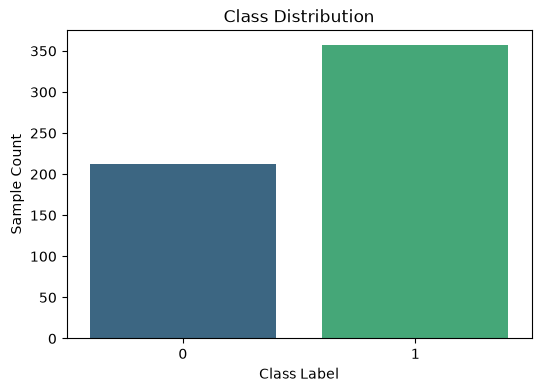

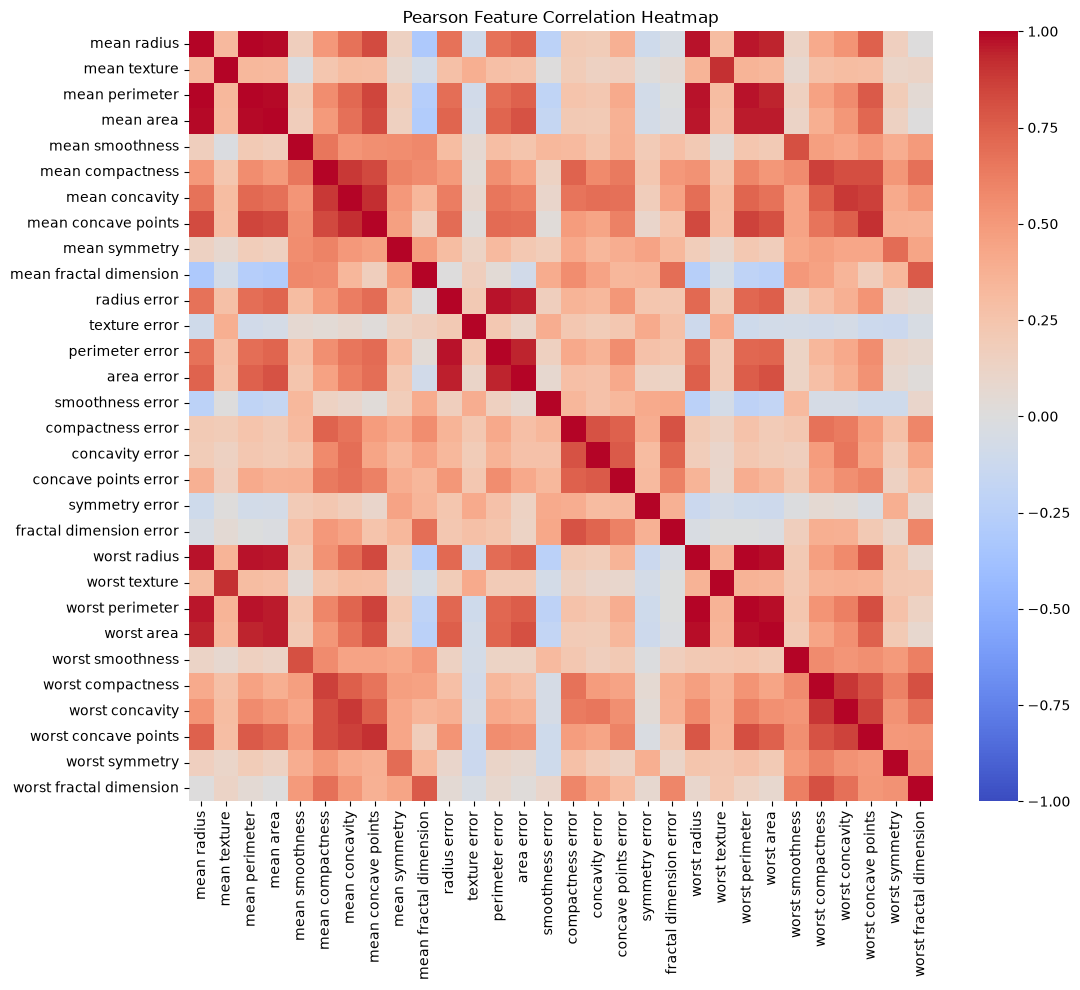

Top 3 unique feature pairs by absolute correlation:
mean radius   mean perimeter     0.997855
worst radius  worst perimeter    0.993708
mean radius   mean area          0.987357
dtype: float64

=== 3.3 Feature Boxplots ===


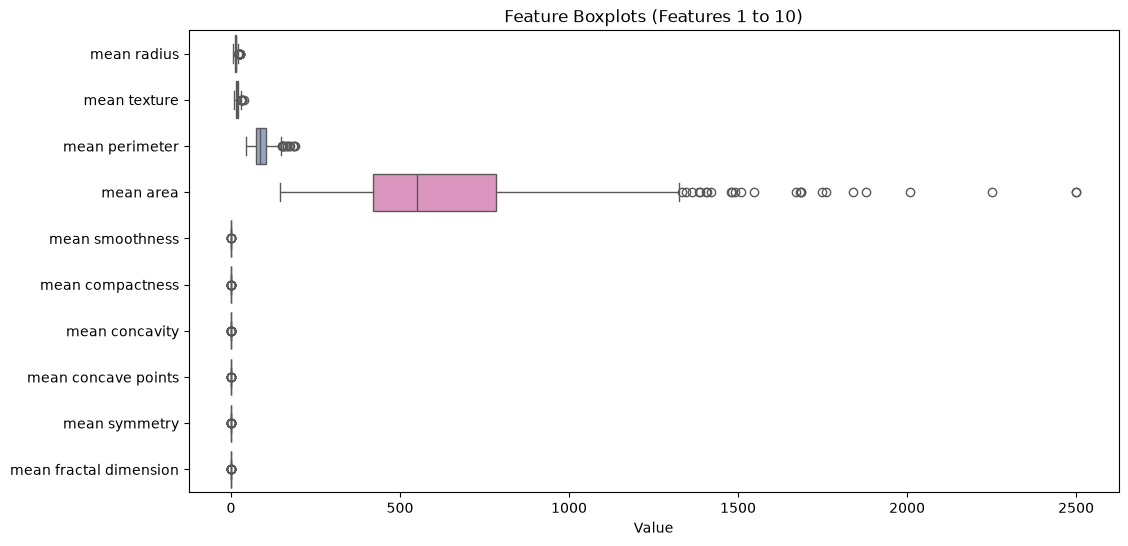

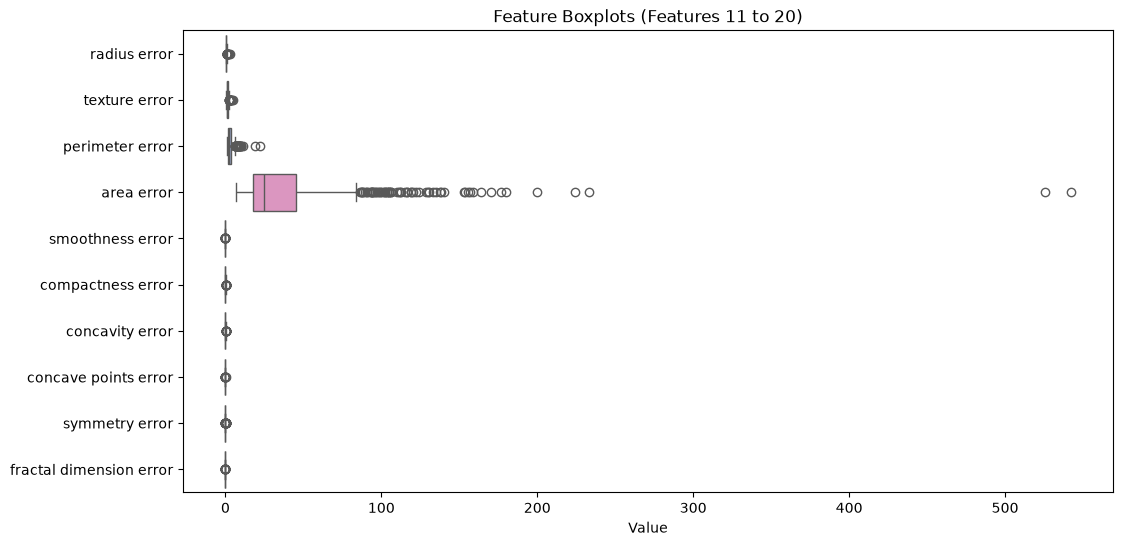

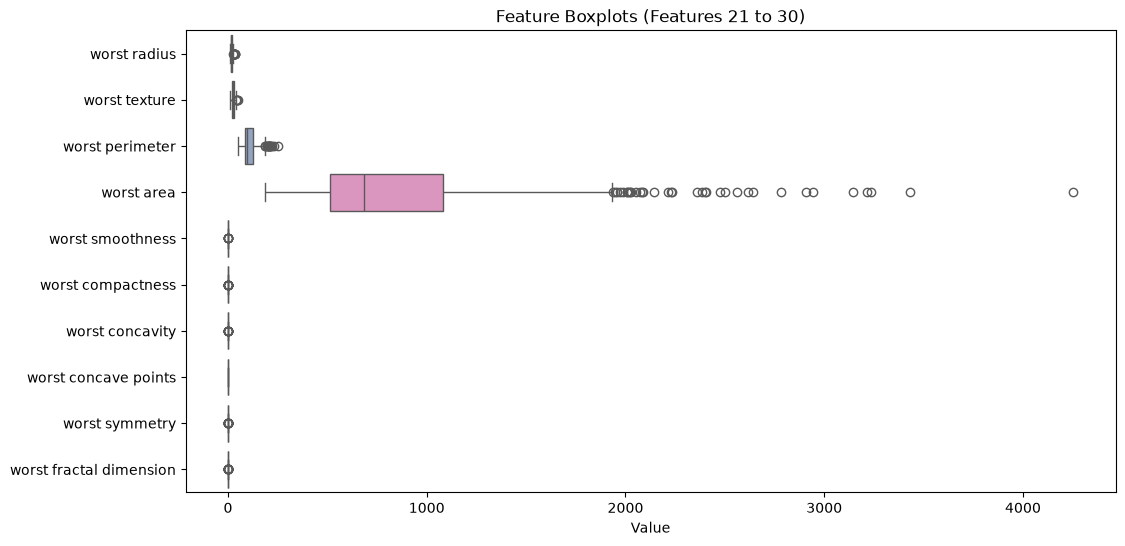

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 3. Exploratory Data Analysis (EDA)
# ==========================================

print("=== 3.1 Descriptive Statistics ===")
# Generate descriptive stats: mean, median (50%), min, max, std, Q1 (25%), Q3 (75%)
desc_stats = X.describe().T[['mean', '50%', 'min', 'max', 'std', '25%', '75%']]
desc_stats = desc_stats.rename(columns={'50%': 'median', '25%': 'Q1', '75%': 'Q3'})
display(desc_stats)

# ==========================================
# 3.2 Class Distribution & Correlations
# ==========================================
print("\n=== 3.2 Class Distribution and Feature Correlations ===")

# Plot Class Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x=y, hue=y, palette="viridis", legend=False)
plt.title("Class Distribution")
plt.savefig("figures/breast_cancer_class_distribution.png", dpi=150, bbox_inches="tight")
plt.xlabel("Class Label")
plt.ylabel("Sample Count")
plt.show()

# Plot Pearson Feature-Correlation Heatmap
plt.figure(figsize=(12, 10))
corr_matrix = X.corr(method='pearson')
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Pearson Feature Correlation Heatmap")
plt.savefig("figures/breast_cancer_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# Extract top 3 unique feature pairs by absolute correlation
upper_triangle = np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)
corr_pairs = corr_matrix.where(upper_triangle).abs().stack().sort_values(ascending=False)
top_3_pairs = corr_pairs.head(3)

print("Top 3 unique feature pairs by absolute correlation:")
print(top_3_pairs)

# ==========================================
# 3.3 Boxplots
# ==========================================
print("\n=== 3.3 Feature Boxplots ===")
# Group features into subsets so boxplots remain readable
features = X.columns
features_per_plot = 10 
num_plots = (len(features) + features_per_plot - 1) // features_per_plot

for i in range(num_plots):
    start_idx = i * features_per_plot
    end_idx = min((i + 1) * features_per_plot, len(features))
    subset_cols = features[start_idx:end_idx]
    
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=X[subset_cols], orient="h", palette="Set2")
    plt.title(f"Feature Boxplots (Features {start_idx+1} to {end_idx})")
    plt.savefig(f"figures/breast_cancer_boxplots_{i+1}.png", dpi=150, bbox_inches="tight")
    plt.xlabel("Value")
    plt.show()

### Section 3 interpretation

The descriptive statistics show substantial differences in scale across the measurements, especially between area/perimeter variables and smoothness-related variables. The strongest unique correlations are among radius, perimeter and area measurements, which is consistent with their shared geometric meaning. The boxplots show potential high-value observations in several measurements; these are retained because the assignment treats them as valid observations, while scaling is evaluated later using training data only.

Sections 4-10 use the fixed stratified test set, three training/validation seeds, training-only StandardScaler preprocessing, the required classifier grid, and K-Means. Results and figures are exported for the combined project inventory.


4-10. BREAST_CANCER

4.2 Split summary, class counts and original indices
      dataset  seed     subset  n_samples  percentage_of_dataset     class_counts                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       indices
breast_cancer    42      train        398              69.947276 {0: 149, 1: 249}        [301, 390, 420, 356, 446, 56, 82, 221, 339, 364, 37, 263, 341, 210, 514, 234, 99, 533, 482, 69, 484, 192, 392, 81, 245, 529, 91, 35, 456, 351, 79, 272, 270, 177, 469, 46, 163, 181, 107, 108, 332, 48, 262, 362, 379, 531, 146, 382, 562, 325, 98, 377, 400, 532, 5

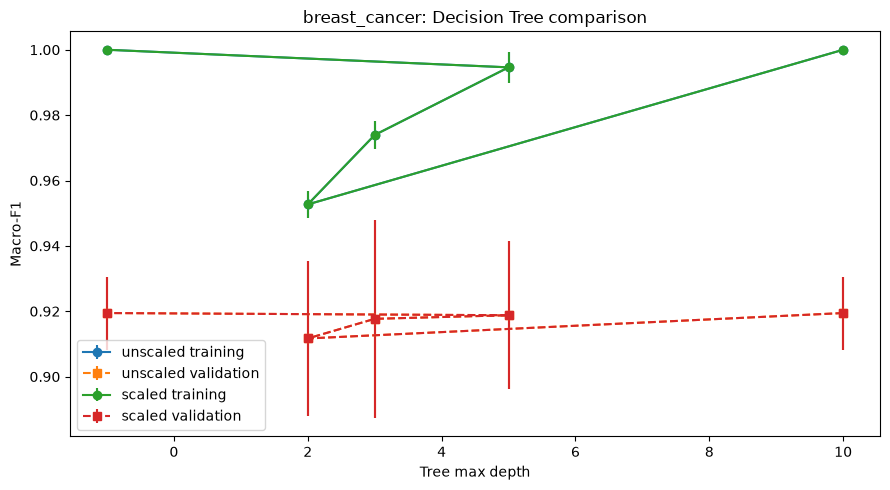

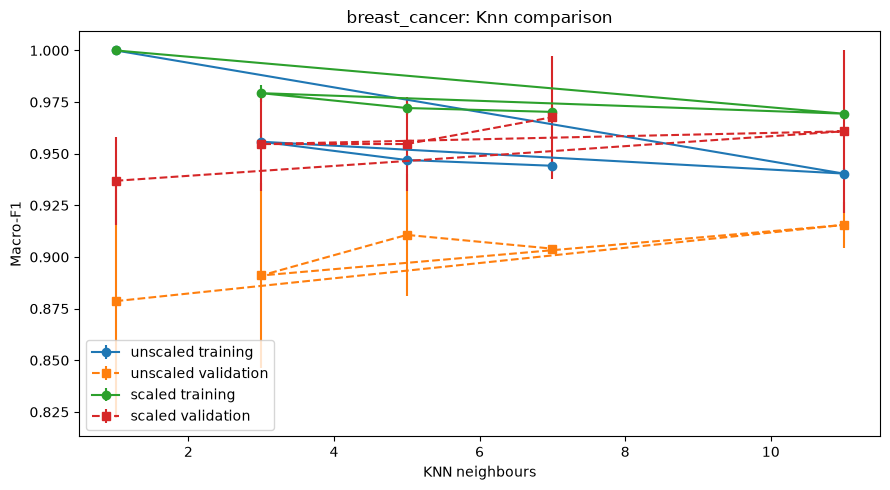


7-9. Classifier results
Classifier runs: 66
Selected configuration:
                                                    0
dataset                                 breast_cancer
selected_configuration_id  breast_cancer_knn_scaled_7
selected_algorithm                                knn
selected_representation                        scaled
selected_parameter                      n_neighbors=7
evaluation_seed                                    42
validation_f1_mean                           0.967675
validation_f1_std                            0.029718
test_accuracy                                0.973684
test_precision_macro                             0.98
test_recall_macro                            0.964286
test_f1_macro                                0.971277
test_roc_auc                                 0.988757
              precision    recall  f1-score   support

   malignant       1.00      0.93      0.96        42
      benign       0.96      1.00      0.98        72

    accurac

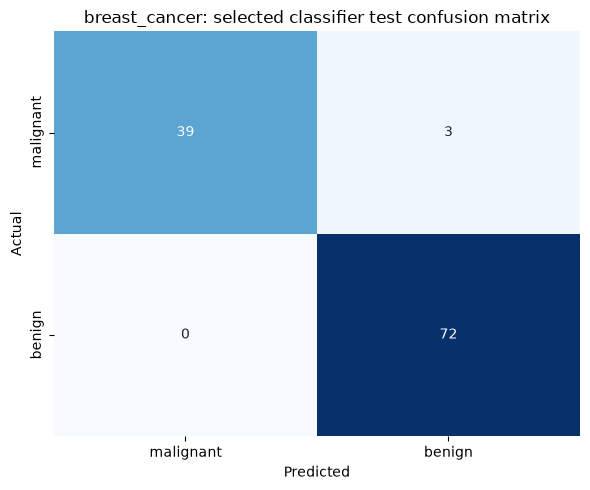

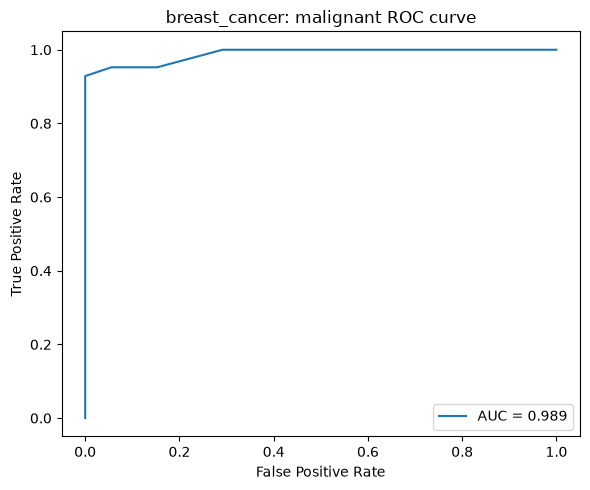

Manual malignant metrics: 1.0 0.9285714285714286 0.962962962962963

unscaled test class/cluster contingency table:
cluster      0   1
true_class        
0           14  28
1           72   0


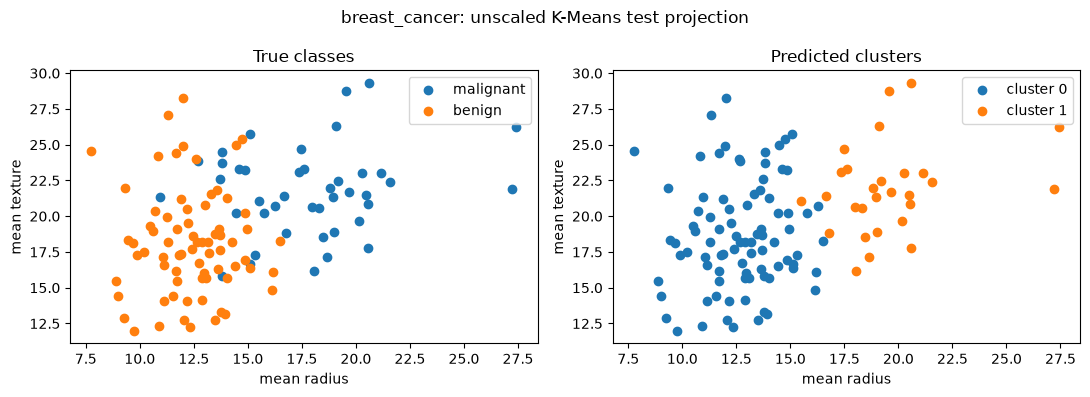


scaled test class/cluster contingency table:
cluster      0   1
true_class        
0            5  37
1           69   3


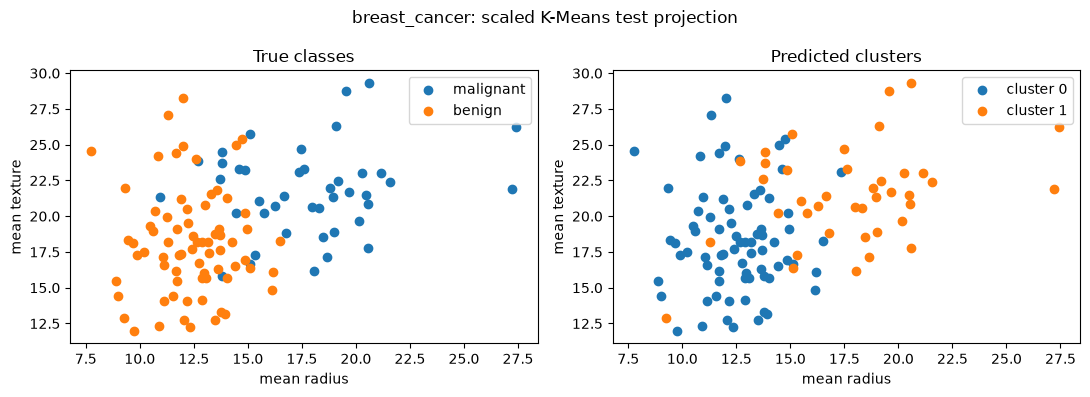


Saved CSV outputs for breast_cancer.


In [4]:
from midterm_pipeline import run_dataset

breast_cancer_results = run_dataset(
    dataset_name="breast_cancer",
    X=X,
    y=y,
    target_names=cancer.target_names,
    n_clusters=2,
    plot_features=["mean radius", "mean texture"],
)

## 4. Splitting the Datasets

Each repetition uses the same fixed 114-row test set and approximately 70/10/20 training, validation and test proportions. The seed changes only the training/validation membership.

## 5. Data Preprocessing and Scaling

No imputation was needed because the quality checks found no missing values. StandardScaler was fitted separately on each training subset, and the original indexed features were retained in both representations.

## 6. Preparing the Two Data Representations

Both representations retain all original features and the same sample indices.

## 7. Training the Classification Models

All 66 required classifier fits were recorded. Scaling is most important for KNN because Euclidean distances are affected by feature units; tree results are unchanged because tree thresholds are not distance-based.

## 8. Measuring Validation Performance

Configurations were selected using mean validation macro-F1, followed by the specified tie-break rules; test scores were not used for selection.

## 9. Evaluating the Selected Model

The selected seed-42 scaled KNN uses seven neighbours. It achieves 0.971 macro-F1 and 0.989 ROC-AUC on the fixed test set. The malignant-class manual precision, recall and F1 are 1.000, 0.929 and 0.963. In the confusion matrix, a malignant false negative is a malignant case predicted as benign; changing the ROC threshold changes the false-positive/false-negative trade-off.

## 10. K-Means Clustering

Scaling improves the Breast Cancer test ARI from 0.558 to 0.735, although silhouette is computed in different feature spaces and should not be compared as if the units were identical. Cluster IDs are not treated as class labels.

## 11. Comparing the Two Datasets

The comparison below is generated from the exported run tables rather than from test performance alone. Validation means and standard deviations describe the three repeated training/validation splits; the fixed seed-42 test results are reported separately.

In [5]:
classifier_summary_all = pd.read_csv("classifier_summary.csv")
classifier_test_all = pd.read_csv("classifier_test.csv")
kmeans_test_all = pd.read_csv("kmeans_test.csv")

print("11. COMPARING THE TWO DATASETS")
print("Best validation configurations:")
for dataset_name in ["breast_cancer", "wine"]:
    rows = classifier_summary_all[classifier_summary_all["dataset"] == dataset_name]
    best = rows.sort_values(
        ["val_f1_macro_mean", "val_accuracy_mean", "val_f1_macro_std", "configuration_id"],
        ascending=[False, False, True, True],
    ).iloc[0]
    print(dataset_name, best[["algorithm", "representation", "parameter", "val_f1_macro_mean", "val_f1_macro_std"]].to_dict())

print("\nFinal classifier results:")
display(classifier_test_all)
print("\nFinal K-Means results:")
display(kmeans_test_all)
print("\nConclusions:")
print("1. Both datasets selected scaled KNN, but the selected neighbour counts differ: 7 for Breast Cancer and 11 for Wine.")
print("2. Scaling affects KNN most: the best mean validation macro-F1 rises from 0.916 to 0.968 for Breast Cancer and from 0.671 to 0.981 for Wine.")
print("3. Deeper trees do not always improve performance: Breast Cancer reaches a plateau at depth 10, while Wine improves sharply after depth 2 and then plateaus. Seed standard deviations show that validation subsets are small and variable.")
print("4. Breast Cancer has malignant false negatives in the selected classifier; Wine has no errors on this fixed test sample, which does not prove perfect generalisation.")
print("5. Scaled K-Means agrees more closely with the labels for both datasets, with test ARI 0.735 for Breast Cancer and 0.909 for Wine. A future investigation would assess additional predeclared validation splits or a different distance-based method, without retuning on the test set.")

11. COMPARING THE TWO DATASETS
Best validation configurations:
breast_cancer {'algorithm': 'knn', 'representation': 'scaled', 'parameter': 'n_neighbors=7', 'val_f1_macro_mean': 0.9676749826749828, 'val_f1_macro_std': 0.029718024557980914}
wine {'algorithm': 'knn', 'representation': 'scaled', 'parameter': 'n_neighbors=11', 'val_f1_macro_mean': 0.9813519813519814, 'val_f1_macro_std': 0.032299315758860164}

Final classifier results:


,dataset,selected_algorithm,selected_representation,selected_parameter,evaluation_seed,validation_f1_mean,validation_f1_std,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_roc_auc,selected_configuration_id
0,wine,knn,scaled,n_neighbors=11,42,0.981352,0.032299,1.000000,1.00,1.000000,1.000000,1.000000,wine_knn_scaled_11
1,breast_cancer,knn,scaled,n_neighbors=7,42,0.967675,0.029718,0.973684,0.98,0.964286,0.971277,0.988757,breast_cancer_knn_scaled_7



Final K-Means results:


,dataset,representation,seed,n_clusters,test_cluster_counts,test_ari,test_silhouette
0,wine,unscaled,42,3,"{0: np.int64(14), 1: np.int64(10), 2: np.int64...",0.373323,0.492880
1,wine,scaled,42,3,"{0: np.int64(13), 1: np.int64(13), 2: np.int64...",0.908794,0.271120
2,breast_cancer,unscaled,42,2,"{0: np.int64(86), 1: np.int64(28)}",0.558488,0.711999
3,breast_cancer,scaled,42,2,"{0: np.int64(74), 1: np.int64(40)}",0.735381,0.325062



Conclusions:
1. Both datasets selected scaled KNN, but the selected neighbour counts differ: 7 for Breast Cancer and 11 for Wine.
2. Scaling affects KNN most: the best mean validation macro-F1 rises from 0.916 to 0.968 for Breast Cancer and from 0.671 to 0.981 for Wine.
3. Deeper trees do not always improve performance: Breast Cancer reaches a plateau at depth 10, while Wine improves sharply after depth 2 and then plateaus. Seed standard deviations show that validation subsets are small and variable.
4. Breast Cancer has malignant false negatives in the selected classifier; Wine has no errors on this fixed test sample, which does not prove perfect generalisation.
5. Scaled K-Means agrees more closely with the labels for both datasets, with test ARI 0.735 for Breast Cancer and 0.909 for Wine. A future investigation would assess additional predeclared validation splits or a different distance-based method, without retuning on the test set.


## 12. Required Run and Output Inventory

The project exports the six required CSV files: 132 classifier runs, 44 classifier-summary rows, 2 classifier-test rows, 12 K-Means runs, 4 K-Means-summary rows and 4 K-Means-test rows. The `figures/` directory contains the required EDA, classifier and clustering figures. The raw run tables remain in CSV format so they can be inspected without copying all rows into the report.